# Car Damages — типы повреждений, Supervisely

Набор повреждений находится в `car-parts-and-damage-dataset/Car parts dataset/`: содержимое определяется по реальным классам из `meta.json`.

Классы: `Dent`, `Cracked`, `Scratch`, `Flaking`, `Broken part`, `Paint chip`, `Missing part`, `Corrosion`. Аннотации лежат в `File1/ann/`, фото ожидаются в `File1/img/`. Полигоны, отверстия и размеры читаются из Supervisely JSON, цвета — из `meta.json`. Сейчас фото отсутствуют: показываются реальные полигоны на сером фоне с подписью об отсутствии изображения.

`SPLIT = "all"`. Пример: `CLASS_FILTER = "Scratch"`.

Запустите ячейки сверху вниз. **Для новой случайной подборки повторите последнюю ячейку.** Настройки: количество фото, выборка, фильтр класса, случайное зерно, контуры, рамки и подписи. Исходные поля выбранной записи: `selected_samples[0]["metadata"]`.


In [1]:
import csv
import json
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [current_dir, *current_dir.parents] if (path / "datasets").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Откройте ноутбук из папки проекта с каталогом datasets/.")
VIEWERS_DIR = PROJECT_ROOT / "code" / "viewers"
if str(VIEWERS_DIR) not in sys.path:
    sys.path.insert(0, str(VIEWERS_DIR))

from viewer_common import (
    IMAGE_SUFFIXES, image_files, load_coco, load_supervisely,
    read_jsonl, show_samples, summarize,
)


In [2]:
DATASET_ROOT = PROJECT_ROOT / "datasets" / "car-parts-and-damage-dataset" / "Car parts dataset"
SPLIT = "all"
N_IMAGES = 4
N_COLS = 2
SEED = None                 # Целое число фиксирует подборку
CLASS_FILTER = None         # Название класса или список; None = все
SHOW_MASKS = True
SHOW_BOXES = True
SHOW_LABELS = True
SHOW_CLASS_IDS = False
ONLY_ANNOTATED = False


In [3]:
dataset, class_metadata = load_supervisely(DATASET_ROOT)
print("Источник классов:", DATASET_ROOT / "meta.json")
summary = summarize(dataset)


Источник классов: C:\Users\nikita\Desktop\Car_Damage_Detection\datasets\car-parts-and-damage-dataset\Car parts dataset\meta.json
Записей: 814; изображения отсутствуют: 814
Выборки: {'all': 814}
Классы (число меток):
  Broken part: 1,500
  Corrosion: 277
  Cracked: 76
  Dent: 1,664
  Flaking: 337
  Missing part: 632
  Paint chip: 1,356
  Scratch: 3,242


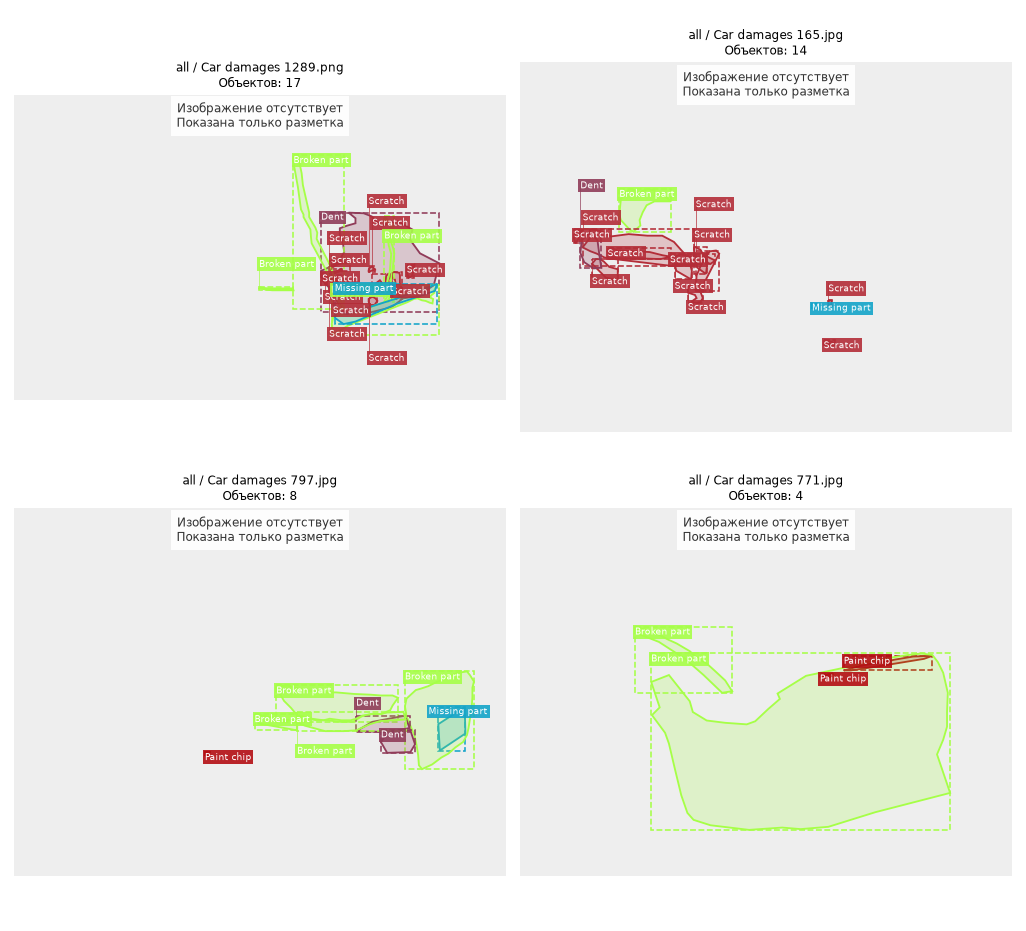

In [4]:
# Повторный запуск этой ячейки показывает новую случайную подборку.
figure, selected_samples = show_samples(
    dataset, n_images=N_IMAGES, n_cols=N_COLS, seed=SEED,
    split=SPLIT, class_filter=CLASS_FILTER,
    show_masks=SHOW_MASKS, show_boxes=SHOW_BOXES,
    show_labels=SHOW_LABELS, show_class_ids=SHOW_CLASS_IDS,
    only_annotated=ONLY_ANNOTATED,
)
